In [24]:
import pandas as pd
import os


os.chdir("../")

In [25]:
# data = pd.read_csv('data/telegram_spam_cleaned.csv')
use_tweet = True
if use_tweet:
    data = pd.read_csv('data/tweets.csv')
    data.rename(columns={"tweet_text": "text"}, inplace=True)
    data.drop(columns=['cyberbullying_type'], inplace=True)
data.drop_duplicates(subset=['text'], inplace=True)
display(data.columns, data.shape)
label = "label"
text = "text"

Index(['text'], dtype='str')

(46017, 1)

In [26]:
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme()
train, test = train_test_split(data, train_size=0.8)

In [27]:
len_symb = train[text].str.len()
len_word = train[text].apply(lambda x: len(x.split()))

36813
137.89718306033194 24.03751392171244


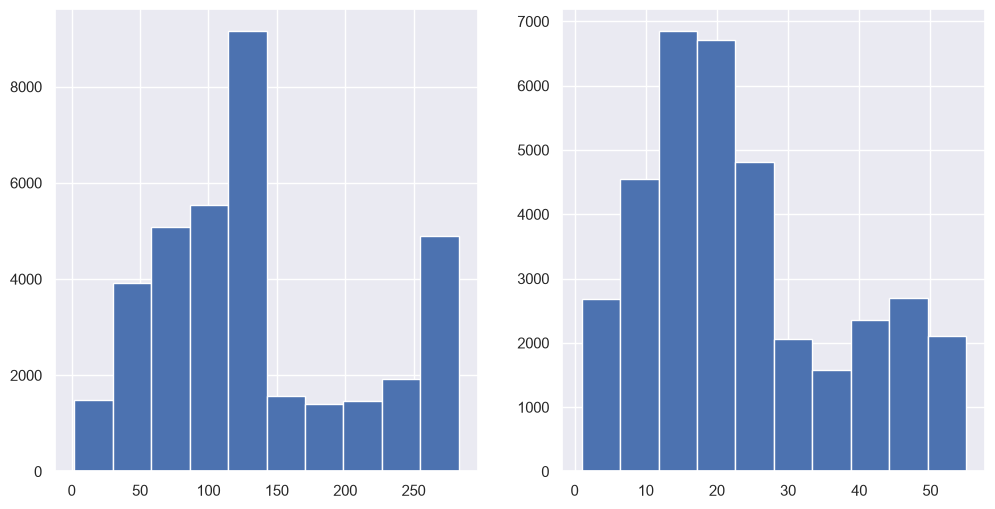

In [28]:
fig, ax = plt.subplots(1, 2, figsize=(12, 6))


ax[0].hist(len_symb[len_symb < len_symb.quantile(0.99)])
ax[1].hist(len_word[len_word < len_word.quantile(0.99)])
print(train.shape[0])
print(len_symb.mean(), len_word.mean())


50756


''

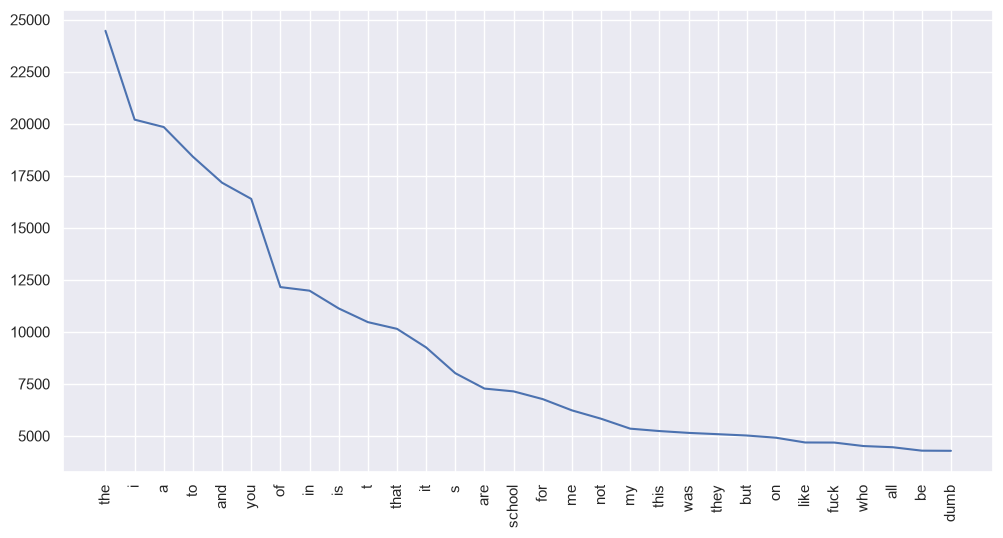

In [29]:
from collections import Counter
def unique_tokens(pd_ser):
    freq = Counter(pd_ser.str.lower().str.findall(r'[а-яa-z]+').explode())
    a = freq.most_common(30)
    x = [i[0] for i in a]
    y = [i[1] for i in a]
    plt.figure(figsize=(12,6))
    plt.plot(x, y)
    plt.xticks(rotation=90)
    print(len(freq))
    return freq
unique_tokens(train.text)
''

In [30]:
import unicodedata as ud
import pandas as pd
from collections import Counter
from itertools import chain

char_freq = Counter(chain.from_iterable(train['text'].dropna()))

df = pd.DataFrame(
    [(ch, f'U+{ord(ch):04X}', ud.category(ch), ud.name(ch, '?'), n)
     for ch, n in char_freq.items()],
    columns=['char', 'code', 'cat', 'name', 'count']
).sort_values('count', ascending=False)
display(df.head(20))
df.tail(20)


,char,code,cat,name,count
3,,U+0020,Zs,SPACE,849215
6,e,U+0065,Ll,LATIN SMALL LETTER E,398372
8,t,U+0074,Ll,LATIN SMALL LETTER T,307308
10,a,U+0061,Ll,LATIN SMALL LETTER A,302724
1,o,U+006F,Ll,LATIN SMALL LETTER O,293945
11,i,U+0069,Ll,LATIN SMALL LETTER I,270423
7,s,U+0073,Ll,LATIN SMALL LETTER S,245495
14,n,U+006E,Ll,LATIN SMALL LETTER N,236212
9,r,U+0072,Ll,LATIN SMALL LETTER R,200923
13,h,U+0068,Ll,LATIN SMALL LETTER H,187743


,char,code,cat,name,count
377,ʃ,U+0283,Ll,LATIN SMALL LETTER ESH,1
416,✎,U+270E,So,LOWER RIGHT PENCIL,1
417,⨾,U+2A3E,Sm,Z NOTATION RELATIONAL COMPOSITION,1
420,,U+E408,Co,?,1
448,足,U+8DB3,Lo,CJK UNIFIED IDEOGRAPH-8DB3,1
461,ک,U+06A9,Lo,ARABIC LETTER KEHEH,1
460,پ,U+067E,Lo,ARABIC LETTER PEH,1
458,❝,U+275D,So,HEAVY DOUBLE TURNED COMMA QUOTATION MARK ORNAMENT,1
452,レ,U+30EC,Lo,KATAKANA LETTER RE,1
450,み,U+307F,Lo,HIRAGANA LETTER MI,1


In [31]:
pd.set_option("display.max_colwidth", 255)

In [32]:
train[text].sample(20)

41726                                                                                                                                                                            Dumb nigger fuck always comes in my room uses my piano and plays one song @Rowellisous
39191    I’m glad at least that the comments seemed to have cleared up more than they were before. They used to be awful and now it’s slightly better. You get the frequent teenager trying to live her middle school bully lifestyle she never got to experience bu...
10803                                                                                                                            not only that but they are so stupid and wrapped up in their "I need to be manly" "that's gay" "rape jokes" stuff JUST SHUT UP ALREADY
41079                                                                                                                                                                                     Watching silent librar

In [33]:
import emoji
import re
def replace_emoji(text, lang='en', sep=' '):
    if not isinstance(text, str):
        return text
    return emoji.replace_emoji(
        text,
        replace=lambda ch, data: f"{sep}{data[lang].strip(':').replace('_', ' ')}{sep}"
    ) 

def replace_url(text):
    p_tg = r'http[s]*://t.me/[a-zA-Z/]+'
    p = r'http[s]*://[a-zA-Z/]+'
    pn = r'[0-9]+'
    p_user = r'@[a-zA-Z_]+'
    text = re.sub(p_tg, '[URL_tg]', text)
    text = re.sub(p, '[URL]', text)
    text = re.sub(pn, '[NUM]', text)
    text = re.sub(p_user, '[USR]', text)
    return text

def replace_bn(text):
    p = r'[\n,.!\'"]'
    return re.sub(r'\s+', ' ', re.sub(p, ' ', text))

def pipeline(text):
    text = text.lower()
    de = replace_emoji(text)
    du = replace_url(de)
    dn = replace_bn(du)
    dn = '<s> ' + dn + ' </s>'
    return dn

In [34]:
train['text_prepared'] = train[text].apply(lambda x: pipeline(x))

In [35]:
train.text_prepared.sample(10)

42114                                      <s> yep of course at it s always me always i m the dumb fuck up cunt nigger that s fine i ll be that  </s>
33020                                 <s> just curious if your kids want to bully other kids at school how much would you support their freedom? </s>
24000                                                                                       <s> [USR] [USR][NUM]klady wait which d&amp;d version </s>
45547                                                                                        <s> [USR][NUM] i didn t call you a nigger dumb fuck </s>
41341                                                       <s> fuck dumb nigger that gave me this charlie horse is preventing me to fall asleep </s>
45715             <s> smh rt [USR]: rt [USR]: please shut the fuck up you always tweeting some dumb nigger ass shit that i never wanna see [USR] </s>
45573    <s> [USR][NUM]noscope shut the fuck up dumb ass i m black i ll say nigger if i damn well pl

### lem & stem

In [36]:
import nltk

nltk.download('stopwords')
nltk.download('punkt', quiet=True)
nltk.download('wordnet', quiet=True)

from nltk.stem import PorterStemmer, SnowballStemmer

import pymorphy3
from nltk.stem import WordNetLemmatizer

[nltk_data] Downloading package stopwords to
[nltk_data]     /Users/eugene/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [37]:
st = SnowballStemmer('russian')
pt = PorterStemmer()
morph = pymorphy3.MorphAnalyzer()
lemmatizer_en = WordNetLemmatizer()

def stem(text):
    return ' '.join([st.stem(i) if len(re.findall('[а-я]', i.lower())) > 0 else pt.stem(i) for i in text.split()])
def lem(text):
    return ' '.join([
        morph.parse(i)[0].normal_form if len(re.findall('[а-я]', i.lower())) > 0 else lemmatizer_en.lemmatize(i) for i in text.split()
    ])

In [38]:
display(stem('белый вид дохода fatting lazy cat sat on a mate нужно [NUM]-[NUM] часа в день принимаем как с опытом так и без возраст от [NUM][NUM] лет пишите + в л'))
lem(('белый вид дохода нужно fatting lazy cat sat on a mate часа в день принимаем как с опытом так и без возраст от [NUM][NUM] лет пишите + в л'))

'бел вид доход fat lazi cat sat on a mate нужн [num]-[num] час в ден принима как с опыт так и без возраст от [num][num] лет пиш + в л'

'белый вид доход нужно fatting lazy cat sat on a mate час в день принимать как с опыт так и без возраст от [NUM][NUM] год писать + в л'

33314


''

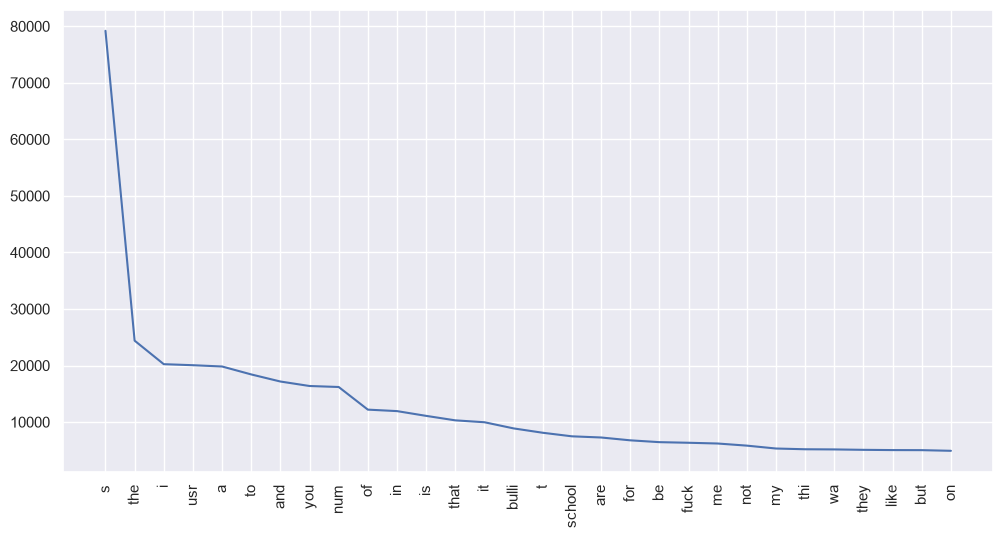

In [39]:
unique_tokens(train.text_prepared.apply(lambda x: stem(x)))
''

38152


''

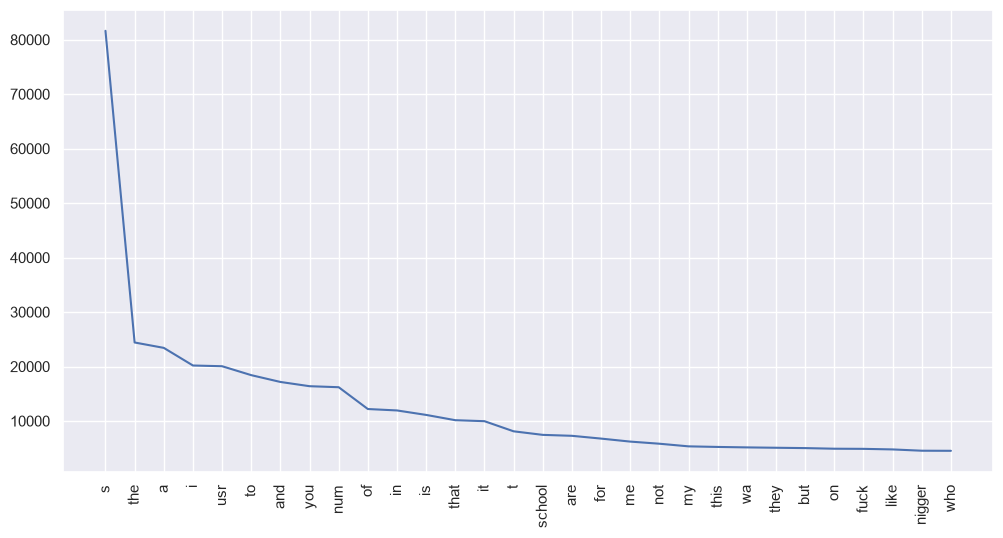

In [40]:
unique_tokens(train.text_prepared.apply(lambda x: lem(x)))
''

### Vocab


In [41]:
train.text_prepared = train[text].apply(lambda x: pipeline(x))
train.text_prepared = train.text_prepared.apply(lambda x: stem(x))

n_unique = 3

vocabulary = Counter(train.text_prepared.str.split().explode())
vocabulary = set([i[0] for i in vocabulary.items() if i[1] > n_unique]) | set(['[UNK]'])
len(vocabulary)

8425

In [42]:
txt = train[text].apply(lambda x: pipeline(x)).sample(1).values[0]
display(stem(txt))
display(lem(txt))

stem(txt) == lem(txt)

'<s> you idiot of minneapoli muslim have you muffl i’ll die befor i celebr anyth muslim enjoy your new fakeass religion </s>'

'<s> you idiot of minneapolis muslim have you muffled i’ll die before i celebrate anything muslim enjoy your new fakeass religion </s>'

False

In [43]:
# vocabulary

In [44]:
def replace_unk(text, vocabulary=vocabulary):
    return " ".join([i if i in vocabulary else '[UNK]' for i in text.split()])

In [45]:
train.text_prepared = train.text_prepared.apply(lambda x: replace_unk(x))
vocabulary_counts = Counter(train.text_prepared.str.split().explode())

### N-gramm test

In [46]:
# fix
# vocabulary_counts['[UNK]'] = 1
depth = 3
stats = {}
for row in train.text_prepared:
    row = row.split()
    for i in range(0, len(row) - depth):
        c = 0
        c_stats = stats
        for c in range(depth - 1):
            word = row[i + c]
            if word == '[UNK]':
                break
            if c < depth - 2:
                c_stats.setdefault(word, {})
                c_stats = c_stats[word]
            
            elif c == depth - 2:
                c_stats.setdefault(word, {})
                fin_word = row[i + c + 1]
                if fin_word == '[UNK]':
                    break
                c_stats[word].setdefault(fin_word, 0)
                c_stats[word][fin_word] += 1
    

# for key in stats.keys():
#     for k2 in stats[key]:
#         stats[key][k2] /= (vocabulary_counts[key] + 1)

In [47]:
# step(['<s>', 'весь',], stats)

In [48]:
def step(prev: list, stats):
    assert len(prev) == depth - 1, 'wrong len list prev'
    for i in prev:
        if not i in stats:
            return '[UNK]'
        stats = stats[i]
        # print(stats, i)
    ans = sorted(stats.items(), key=lambda x:x[1], reverse=True)
    if len(ans) == 0:
        return '[UNK]'
    return ans[0][0]

def inference(text, stats):
    ans = text[::]
    tokens = text.split()[-depth + 1:]
    i = 0
    next_token = ''
    while next_token != '</s>':
        # print(tokens)
        next_token = step(tokens, stats)
        ans += ' ' + next_token
        tokens = tokens[1:] + [next_token]
        i += 1
        if i == 50:
            print('limit')
            break
    ans += ' </s>'
    return ans
        
    

In [49]:
stats['sheesh']

{'river': {'is': 1},
 'ignor': {'as': 1},
 '[usr]': {'hey': 1},
 '&#[num];': {'damn': 1},
 'and': {'don’t': 1}}

In [50]:
print(inference('<s> hello you', stats))
print(inference('<s> [usr] i', stats))
print(inference('<s> sheesh', stats))
print(inference('<s> games', stats))
print(inference('<s> time', stats))

limit
<s> hello you absolut idiot where were you when i wa bulli in high school bulli who peak in high school bulli who peak in high school bulli who peak in high school bulli who peak in high school bulli who peak in high school bulli who peak in high school bulli who </s>
limit
<s> [usr] i m not sexist but i m not sexist but i m not sexist but i m not sexist but i m not sexist but i m not sexist but i m not sexist but i m not sexist but i m not sexist but i m not sexist but i </s>
limit
<s> sheesh river is such a bulli in high school bulli who peak in high school bulli who peak in high school bulli who peak in high school bulli who peak in high school bulli who peak in high school bulli who peak in high school bulli who peak in high school </s>
limit
<s> games [UNK] [UNK] [UNK] [UNK] [UNK] [UNK] [UNK] [UNK] [UNK] [UNK] [UNK] [UNK] [UNK] [UNK] [UNK] [UNK] [UNK] [UNK] [UNK] [UNK] [UNK] [UNK] [UNK] [UNK] [UNK] [UNK] [UNK] [UNK] [UNK] [UNK] [UNK] [UNK] [UNK] [UNK] [UNK] [UNK] [UNK] [UNK]

## N-gramm norm

In [51]:
import collections
bigrams = []
unigrams = []
for row in train.text_prepared:
    tokens = row.split()
    bigrams.extend([(tokens[i], tokens[i + 1]) for i in range(len(tokens) - 1) if not any([tokens[i] == "[UNK]", tokens[i + 1] == "[UNK]"])])
    unigrams.extend([(tokens[i],)for i in range(len(tokens) - 1) if not any([tokens[i] == "[UNK]"])])
bigram_counts = collections.Counter(bigrams)
unigram_counts = collections.Counter(unigrams)

In [52]:
bigram_counts.most_common(5)

[(('<s>', '[usr]'), 6509),
 (('high', 'school'), 3577),
 (('[usr]', '[usr]'), 3231),
 (('<s>', 'i'), 2807),
 (('<s>', 'rt'), 2422)]

In [53]:
from typing import Dict
depth = 2

    
def inference(source_text, score_func):
    ans = text[::]
    tokens = text.split()[-depth + 1:]
    i = 0
    next_token = ''
    while next_token != '</s>':
        # print(tokens)
        next_token = score_func(*tokens, **kwargs)
        ans += ' ' + next_token
        tokens = tokens[1:] + [next_token]
        i += 1
        if i == 50:
            print('limit')
            break
    ans += ' </s>'
    return ans

In [54]:
v_size = len(vocabulary)
def laplasse_add(*words, **kwargs):
    up = bigram_counts.get((words), 0)
    down = unigram_counts.get((words[:-1]), 0)
    return (up + kwargs['alpha']) / (down + v_size * kwargs['alpha'])

In [55]:
import numpy as np
def perplexity(text: str, score_func):
    tokens = text.split()
    N = len(tokens)
    array = np.array([np.log2(score_func(tokens[i], tokens[i + 1], **kwargs)) for i in range(N - 1)])
    # print(array)
    sm = array.sum()
    return 2 ** (-(1/N) * sm)


def perplexity_on_df(df, score_func, text="text_prepared"):
    return df[text].apply(lambda x: perplexity(x, score_func))

In [56]:
kwargs = {'alpha': 0.1}
perplexity_on_df(train, laplasse_add).mean()

np.float64(315.55737693702474)

### test on test

In [57]:
test['text_prepared'] = test[text].apply(lambda x: pipeline(x))
test['text_prepared'] = test.text_prepared.apply(lambda x: stem(x))
kwargs = {'alpha': 0.1}
perplexity_on_df(test, laplasse_add).mean()

np.float64(561.9724361722164)

In [58]:
kwargs = {'alpha': 0}
perplexity_on_df(test, laplasse_add).mean()

/var/folders/8k/pf6tyzbs6fb8nk60l1m38lym0000gp/T/ipykernel_17440/2813345464.py:5: RuntimeWarning: divide by zero encountered in log2
  array = np.array([np.log2(score_func(tokens[i], tokens[i + 1], **kwargs)) for i in range(N - 1)])


ZeroDivisionError: division by zero

In [59]:
bigram_counts.get(('<s>', 'hi'))

35

In [60]:
bigram_counts.most_common(5)

[(('<s>', '[usr]'), 6509),
 (('high', 'school'), 3577),
 (('[usr]', '[usr]'), 3231),
 (('<s>', 'i'), 2807),
 (('<s>', 'rt'), 2422)]

In [61]:
laplasse_add(*'<s> [USR]'.split(), **kwargs)

0.0

In [62]:
laplasse_add(*'<s> [USR]'.split(), alpha=0)

0.0

In [63]:
def print_m(m):
    for i in range(len(m)):
        for j in range(len(m[0])):
             print(str(m[i][j]).ljust(2, " "), end='')
        print()
def lev(s1, s2):
    def calc():
        return min(
            [
                matrix[i][j - 1] + 1,
                matrix[i - 1][j] + 1,
                matrix[i - 1][j - 1] + (1 if s1[j] != s2[i] else 0)
            ]
        )
    matrix = [[0 for i in range(len(s1))] for j in range(len(s2))]
    for i in range(len(s1)):
        matrix[0][i] = i
    for i in range(len(s2)):
        matrix[i][0] = i

    for i in range(1, len(s2)):
        for j in range(1, len(s1)):
            matrix[i][j] = calc()
    return matrix[-1][-1]
lev('bba', 'bboo')


2

In [69]:
import tqdm
pairs = []
k = 3
for target in tqdm.tqdm(list(vocabulary)):
    for sec in list(vocabulary):
        if abs(len(target) - len(sec)) >= k:
            continue
        if len(set(target).symmetric_difference(set(sec))) >= k:
            continue
        l = lev(target, sec)
        if l < k and l > 0:
            pairs.append((target, sec, l))


100%|█████████████████████████████████████████████████████████████████████████████| 8425/8425 [00:43<00:00, 194.20it/s]


In [73]:
ans = []
for i in range(len(pairs)):
    ans.append(vocabulary_counts[pairs[i][0]] + vocabulary_counts[pairs[i][1]])

In [76]:

sorted(zip(pairs, ans), key=lambda x:x[1], reverse=True)[20:30]

[(('the', 't', 2), 29731),
 (('t', 'the', 2), 29731),
 (('the', 'thi', 1), 29410),
 (('thi', 'the', 1), 29410),
 (('the', 'they', 1), 29093),
 (('they', 'the', 1), 29093),
 (('it', 'i', 1), 27713),
 (('i', 'it', 1), 27713),
 (('the', 'he', 1), 27652),
 (('he', 'the', 1), 27652)]